<a href="https://colab.research.google.com/github/kananshr13/CSET-343-Ai-in-Healthcare/blob/main/Lab_Assignment_11_CSET343.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install kagglehub shap seaborn scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import shap

import warnings
warnings.filterwarnings("ignore")

In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "andrewmvd/heart-failure-clinical-data"
)

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'heart-failure-clinical-data' dataset.
Dataset downloaded to: /kaggle/input/heart-failure-clinical-data


In [4]:
import os

files = os.listdir(path)

print(files)

csv_file = [
    file for file in files
    if file.endswith(".csv")
][0]

df = pd.read_csv(
    os.path.join(path, csv_file)
)

df.head()

['heart_failure_clinical_records_dataset.csv']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [5]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Dataset Shape: (299, 13)

Column Names:
Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='object')

Data Types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing Values:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                

In [6]:

df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


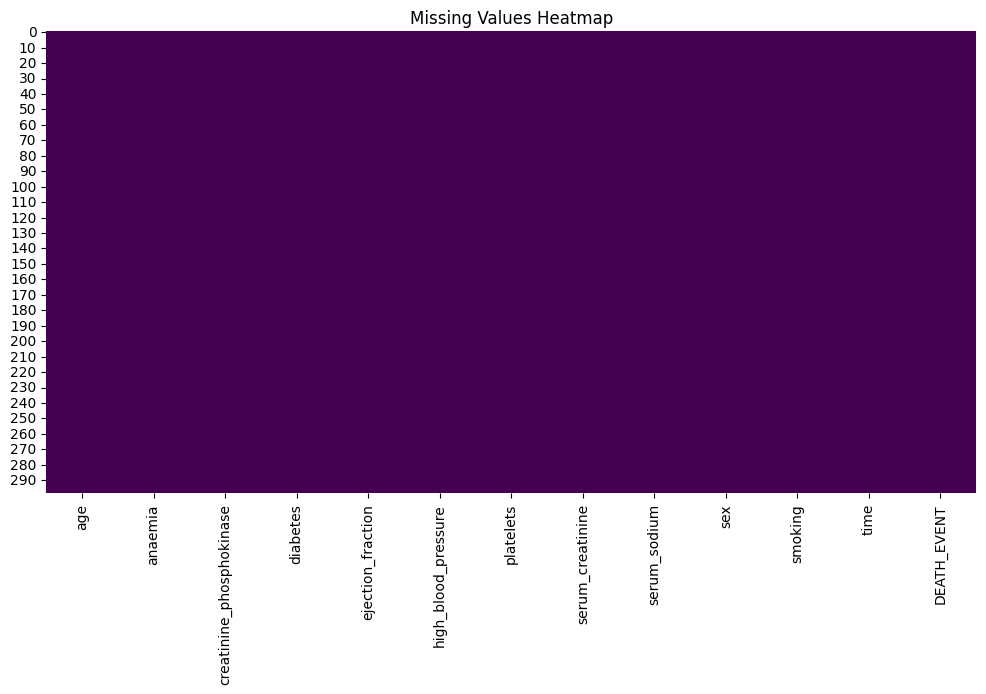

In [7]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cmap="viridis",
    cbar=False
)

plt.title("Missing Values Heatmap")
plt.show()

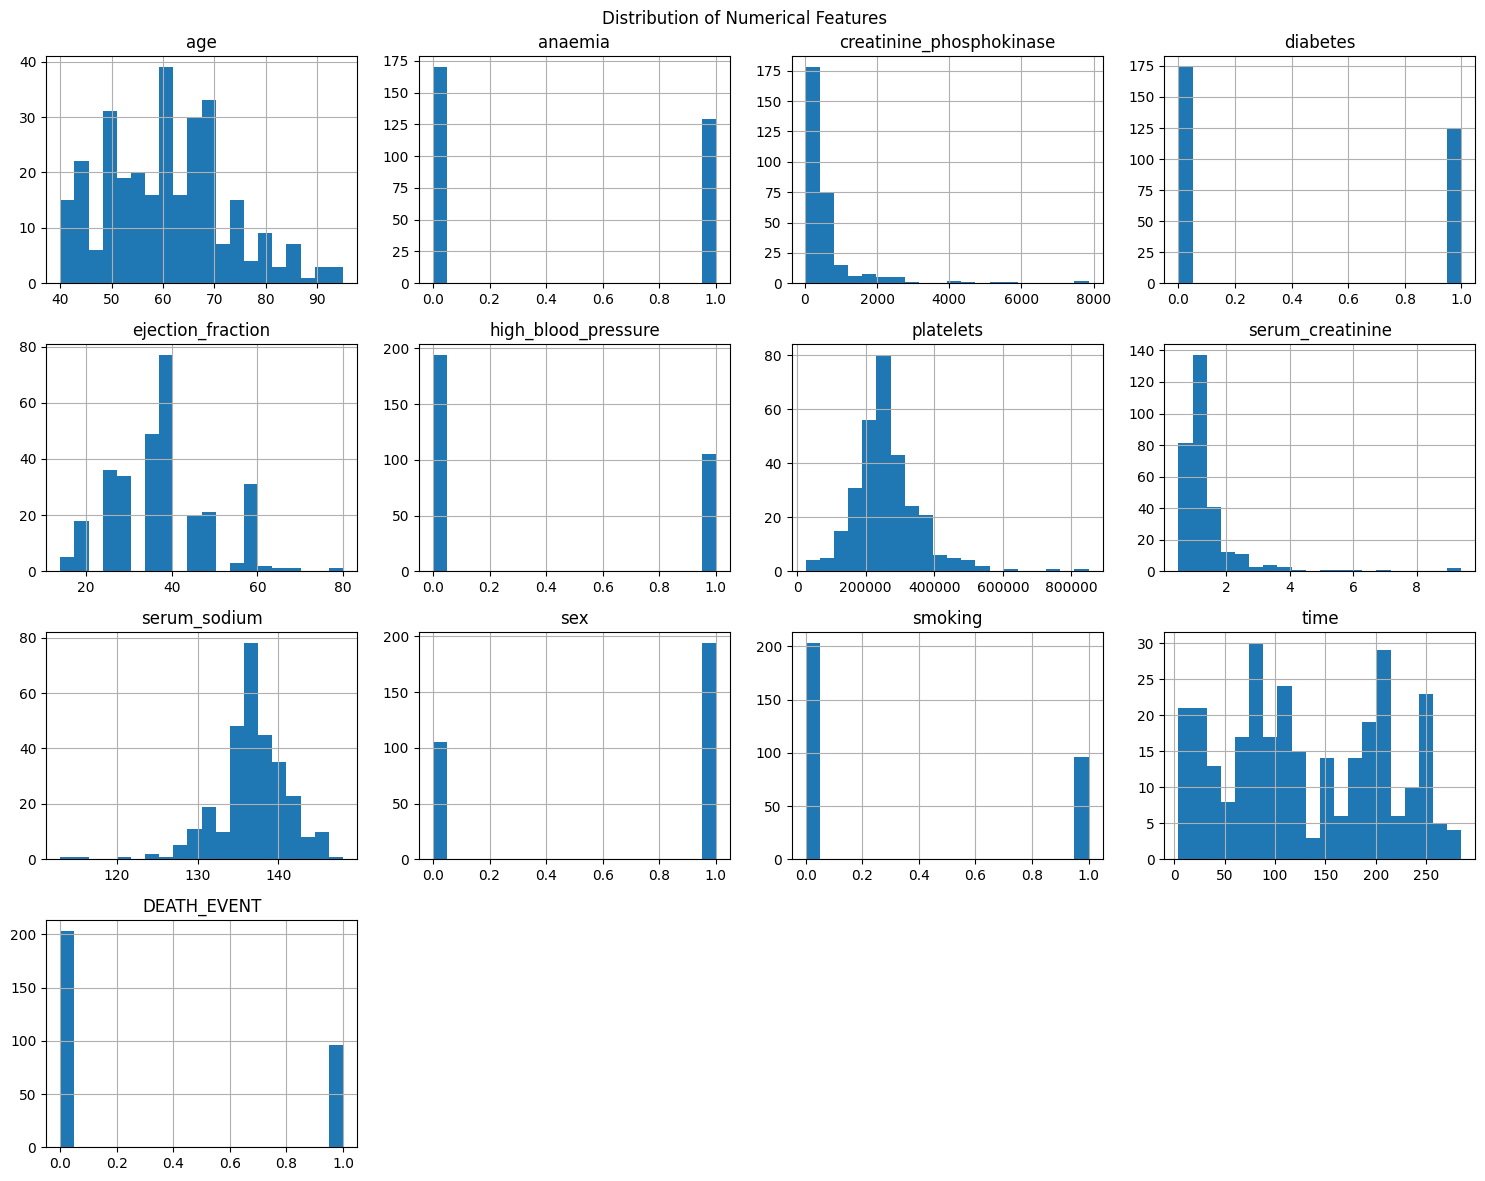

In [8]:

numerical_features = df.select_dtypes(
    include=np.number
).columns

df[numerical_features].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()

plt.show()

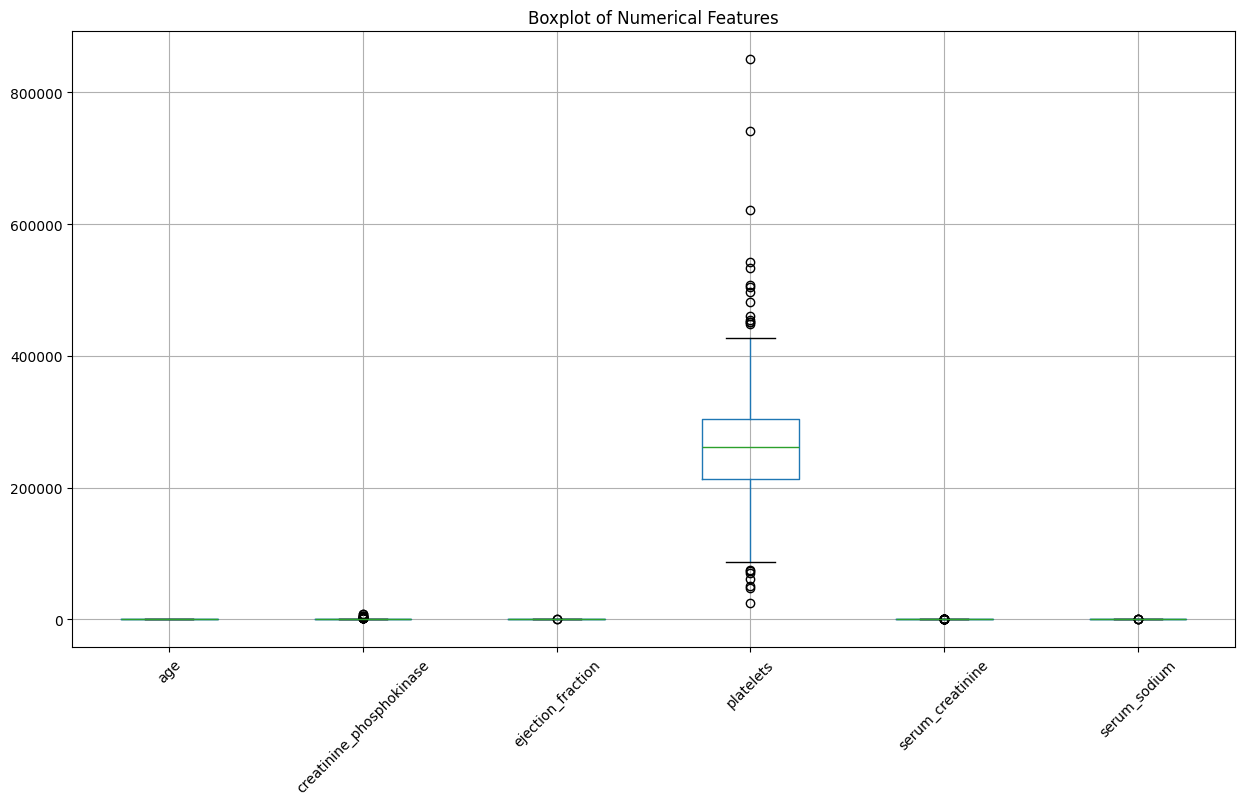

In [9]:

plt.figure(figsize=(15, 8))

df.boxplot(
    column=[
        "age",
        "creatinine_phosphokinase",
        "ejection_fraction",
        "platelets",
        "serum_creatinine",
        "serum_sodium"
    ]
)

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)

plt.show()

In [11]:

print("Missing values before:")
print(df.isnull().sum())

numerical_columns = df.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:

    df[column] = df[column].fillna(
        df[column].median()
    )

print("\nMissing values after:")
print(df.isnull().sum())

Missing values before:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Missing values after:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


In [12]:

numerical_columns = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = df[column].clip(
        lower_bound,
        upper_bound
    )

print("Outliers handled successfully!")

Outliers handled successfully!


In [13]:

# Check for invalid age values

print("Age range:")
print(df["age"].min(), df["age"].max())

# Remove invalid ages

df = df[
    (df["age"] > 0) &
    (df["age"] < 120)
]

# Check binary variables

binary_columns = [
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking"
]

for column in binary_columns:

    print(
        column,
        df[column].unique()
    )

Age range:
40.0 95.0
anaemia [0 1]
diabetes [0 1]
high_blood_pressure [1 0]
sex [1 0]
smoking [0 1]


In [14]:

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 40, 60, 120],
    labels=["Below 40", "40-60", "Above 60"],
    right=False
)

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,age_group
0,75.0,0,582.00,0,20.0,1,265000.00,1.90,130,1,0,4,1,Above 60
1,55.0,0,1280.25,0,38.0,0,263358.03,1.10,136,1,0,6,1,40-60
2,65.0,0,146.00,0,20.0,0,162000.00,1.30,129,1,1,7,1,Above 60
3,50.0,1,111.00,0,20.0,0,210000.00,1.90,137,1,0,7,1,40-60
4,65.0,1,160.00,1,20.0,0,327000.00,2.15,125,0,0,8,1,Above 60


In [15]:

df["risk_score"] = (
    df["ejection_fraction"] *
    df["serum_creatinine"]
)

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,age_group,risk_score
0,75.0,0,582.00,0,20.0,1,265000.00,1.90,130,1,0,4,1,Above 60,38.0
1,55.0,0,1280.25,0,38.0,0,263358.03,1.10,136,1,0,6,1,40-60,41.8
2,65.0,0,146.00,0,20.0,0,162000.00,1.30,129,1,1,7,1,Above 60,26.0
3,50.0,1,111.00,0,20.0,0,210000.00,1.90,137,1,0,7,1,40-60,38.0
4,65.0,1,160.00,1,20.0,0,327000.00,2.15,125,0,0,8,1,Above 60,43.0


In [16]:

df = pd.get_dummies(
    df,
    columns=["age_group"],
    drop_first=True
)

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,risk_score,age_group_40-60,age_group_Above 60
0,75.0,0,582.00,0,20.0,1,265000.00,1.90,130,1,0,4,1,38.0,False,True
1,55.0,0,1280.25,0,38.0,0,263358.03,1.10,136,1,0,6,1,41.8,True,False
2,65.0,0,146.00,0,20.0,0,162000.00,1.30,129,1,1,7,1,26.0,False,True
3,50.0,1,111.00,0,20.0,0,210000.00,1.90,137,1,0,7,1,38.0,True,False
4,65.0,1,160.00,1,20.0,0,327000.00,2.15,125,0,0,8,1,43.0,False,True


In [17]:

X = df.drop(
    "DEATH_EVENT",
    axis=1
)

y = df["DEATH_EVENT"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (299, 15)
Target shape: (299,)


In [18]:

scaler = MinMaxScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

X_scaled.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,risk_score,age_group_40-60,age_group_Above 60
0,0.636364,0.0,0.444621,0.0,0.112150,1.0,0.519231,0.848485,0.217391,1.0,0.0,0.000000,0.200112,0.0,1.0
1,0.272727,0.0,1.000000,0.0,0.448598,0.0,0.514720,0.363636,0.478261,1.0,0.0,0.007117,0.228486,1.0,0.0
2,0.454545,0.0,0.097833,0.0,0.112150,0.0,0.236264,0.484848,0.173913,1.0,1.0,0.010676,0.110510,0.0,1.0
3,0.181818,1.0,0.069994,0.0,0.112150,0.0,0.368132,0.848485,0.521739,1.0,0.0,0.010676,0.200112,1.0,0.0
4,0.454545,1.0,0.108968,1.0,0.112150,0.0,0.689560,1.000000,0.000000,0.0,0.0,0.014235,0.237446,0.0,1.0


In [19]:

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (239, 15)
Testing shape: (60, 15)


In [20]:

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(
    X_train,
    y_train
)

print("Model training completed!")

Model training completed!


In [22]:

y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[0 0 0 0 0 0 0 0 0 1]


In [23]:

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8166666666666667
Precision: 0.7857142857142857
Recall: 0.5789473684210527
F1 Score: 0.6666666666666666


In [24]:

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.83      0.93      0.87        41
           1       0.79      0.58      0.67        19

    accuracy                           0.82        60
   macro avg       0.81      0.75      0.77        60
weighted avg       0.81      0.82      0.81        60



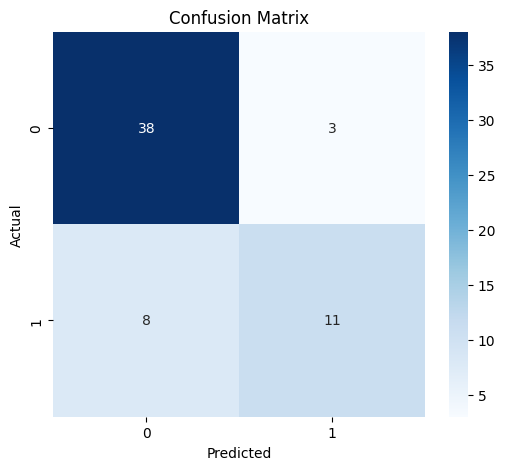

In [25]:

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [26]:

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
11,time,0.307269
7,serum_creatinine,0.129867
4,ejection_fraction,0.121975
12,risk_score,0.091964
0,age,0.071410
6,platelets,0.069214
8,serum_sodium,0.061776
2,creatinine_phosphokinase,0.057743
1,anaemia,0.016706
3,diabetes,0.014903


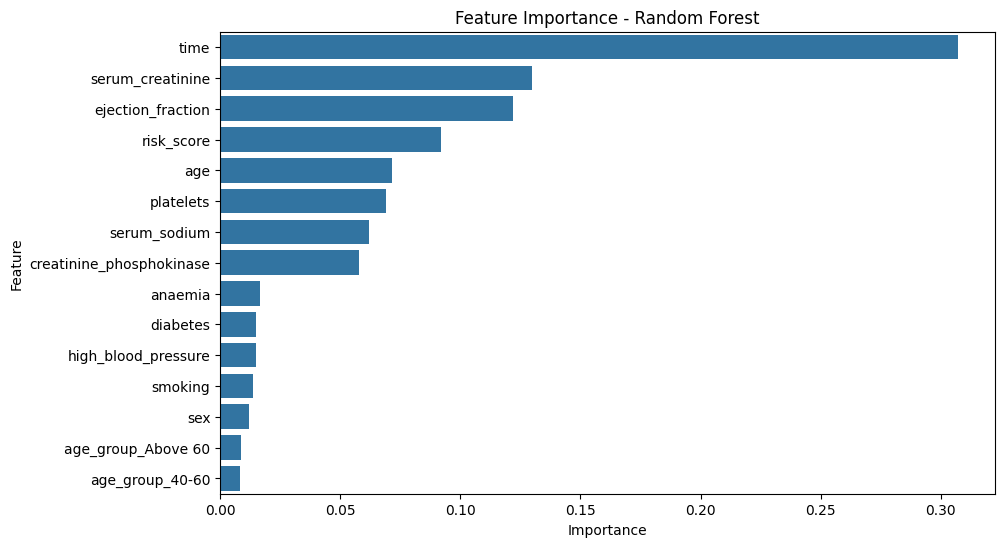

In [27]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.show()

In [28]:

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(
    X_test
)

print("SHAP values generated!")

SHAP values generated!


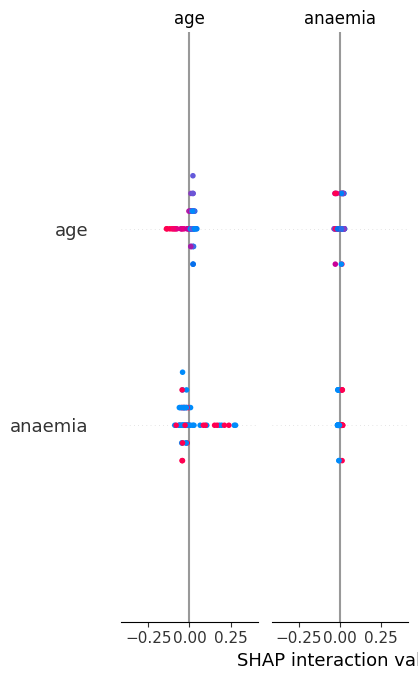

In [29]:

shap.summary_plot(
    shap_values,
    X_test
)

In [30]:

sample_index = 0

sample = X_test.iloc[
    sample_index:sample_index + 1
]

prediction = model.predict(sample)

probability = model.predict_proba(sample)

print("Predicted Class:", prediction[0])

print(
    "Probability:",
    probability
)

print(
    "Actual Class:",
    y_test.iloc[sample_index]
)

Predicted Class: 0
Probability: [[0.8 0.2]]
Actual Class: 0


In [32]:

shap.initjs()

shap.force_plot(
    explainer.expected_value[1],
    shap_values[1][sample_index],
    X_test.iloc[sample_index]
)